# 02 — Exploração dos dados

**Objetivo:** entender a base limpa antes de modelar e fixar o mínimo de meses por mercado da Q3.

O que esta etapa mostra:
1. a série do preço geral (mediana entre mercados, decisões 3 e 10) de cada produto;
2. quantos mercados entram em cada mediana, mês a mês;
3. quantos meses cada mercado tem, para **justificar `config.MIN_MESES_MERCADO`** (decisão 4);
4. quanto os preços variam de um mês para o outro (contexto para a Q1).

Entrada: `data/processed/icb_limpo.csv` (gerado pelo notebook 01). Figuras em `reports/figures/`, tabelas em `reports/tables/`.

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote src/ a partir da pasta notebooks/
sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

from src import aggregation, config, data_loading

# Estilo dos gráficos: uma cor para os dados, cinza para contexto, grade discreta.
AZUL, CINZA, TEXTO, TEXTO_2 = "#2a78d6", "#b5b3ad", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": CINZA, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.titlecolor": TEXTO, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
config.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
config.DIR_TABELAS.mkdir(parents=True, exist_ok=True)

base = data_loading.carregar_base_limpa()
geral = aggregation.serie_geral(base)
print(f"base limpa: {len(base):,} linhas | série geral: {geral['produto'].nunique()} produtos x {geral['mes'].nunique()} meses")

base limpa: 41,029 linhas | série geral: 14 produtos x 48 meses


## 1. Preço geral de cada produto

Cada painel é a mediana entre mercados do PPK (R$ por kg, litro ou unidade). Cada produto tem a sua escala, porque o objetivo é ver o **formato** da série (tendência, sazonalidade, saltos), não comparar níveis de preço.

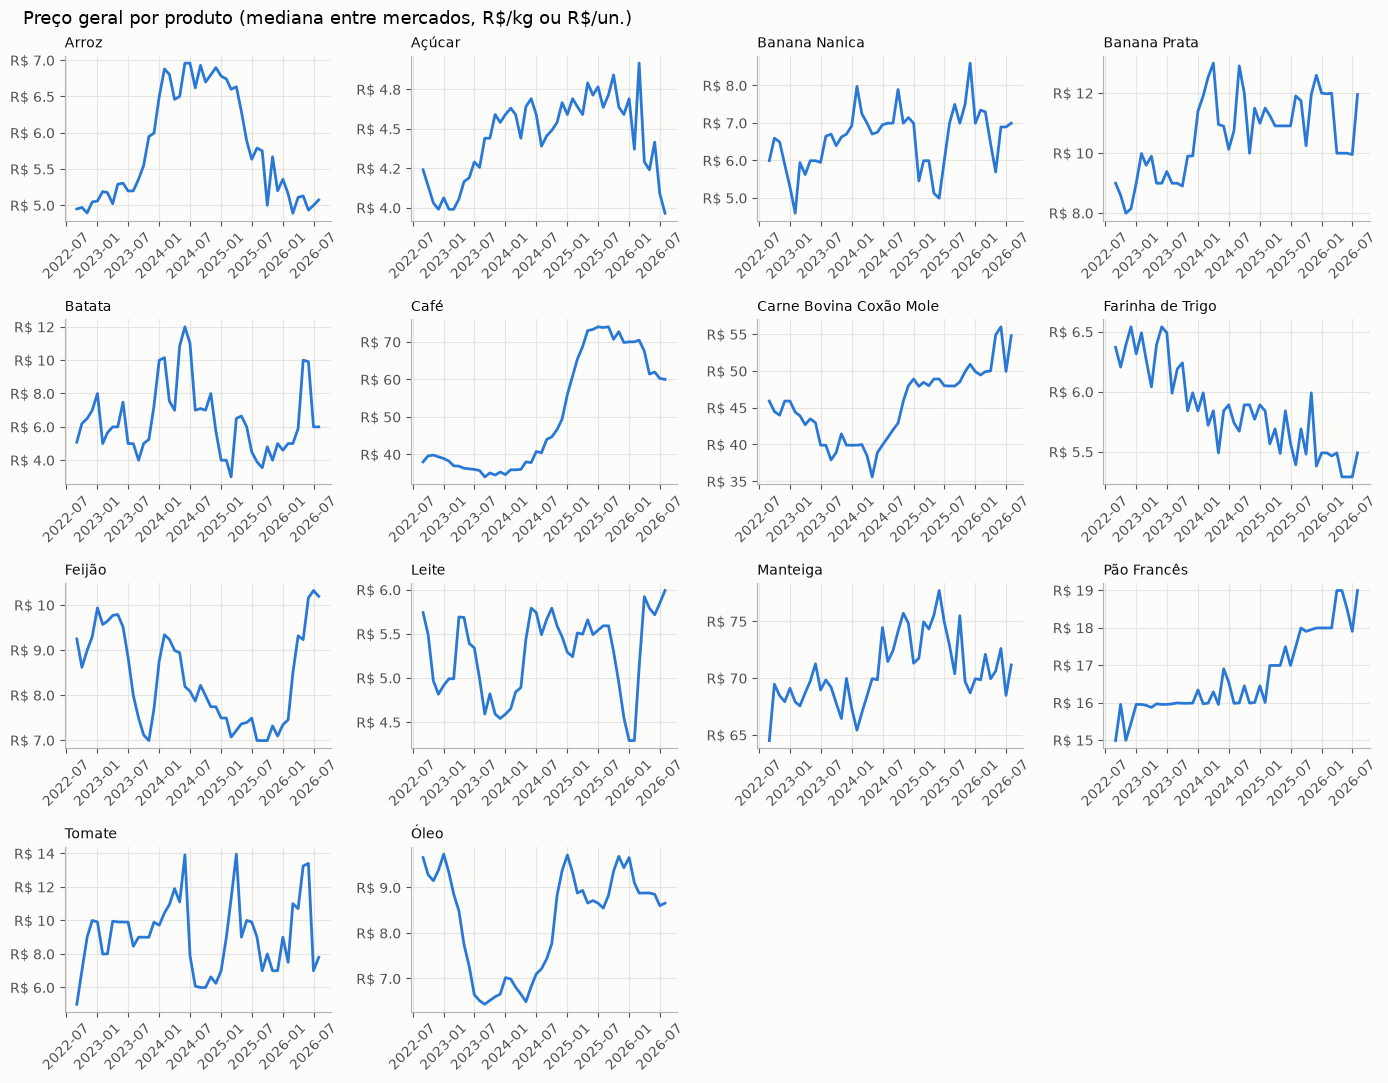

In [2]:
def formato_reais(valor, _):
    return f"R$ {valor:.0f}" if valor >= 10 else f"R$ {valor:.1f}"

produtos = sorted(geral["produto"].unique())
fig, eixos = plt.subplots(4, 4, figsize=(14, 11), sharex=True)
for eixo, produto in zip(eixos.flat, produtos):
    serie = geral[geral["produto"] == produto]
    eixo.plot(serie["mes"].dt.to_timestamp(), serie["preco"], color=AZUL, linewidth=2)
    eixo.set_title(produto, fontsize=10, loc="left")
    eixo.yaxis.set_major_formatter(formato_reais)
for eixo in eixos.flat[len(produtos):]:
    eixo.set_visible(False)
for eixo in eixos.flat:
    eixo.tick_params(axis="x", rotation=45, labelbottom=True)
fig.suptitle(r"Preço geral por produto (mediana entre mercados, R\$/kg ou R\$/un.)", x=0.02, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "02_serie_geral_produtos.png", dpi=150)
plt.show()

## 2. Quantos mercados entram em cada mediana

A mediana é confiável quando reúne muitos mercados. A linha mostra quantos mercados distintos foram coletados em cada mês (todos os produtos).

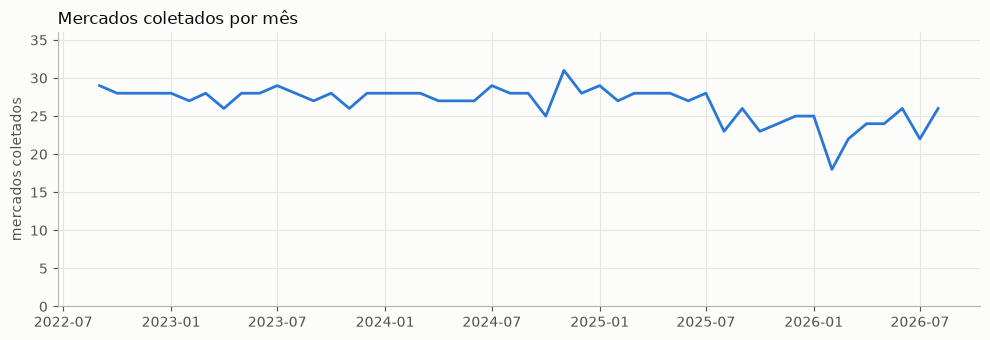

média: 26.7 | mínimo: 18 (2026-02) | máximo: 31


In [3]:
mercados_mes = base.groupby(base[config.COL_MES].dt.to_period("M"))[config.COL_MERCADO].nunique()

fig, eixo = plt.subplots(figsize=(10, 3.5))
eixo.plot(mercados_mes.index.to_timestamp(), mercados_mes.values, color=AZUL, linewidth=2)
eixo.set_ylim(0, mercados_mes.max() + 5)
eixo.set_ylabel("mercados coletados")
eixo.set_title("Mercados coletados por mês", loc="left")
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "02_mercados_por_mes.png", dpi=150)
plt.show()

print(f"média: {mercados_mes.mean():.1f} | mínimo: {mercados_mes.min()} ({mercados_mes.idxmin()}) | máximo: {mercados_mes.max()}")

In [4]:
# Mínimo, mediana e máximo de mercados na mediana de cada produto
geral.groupby("produto")["n_mercados"].agg(["min", "median", "max"]).sort_values("min")

,min,median,max
produto,,,
Banana Nanica,8,25.5,29
Banana Prata,12,25.0,29
Açúcar,15,27.0,31
Manteiga,15,27.0,31
Pão Francês,16,22.0,26
Farinha de Trigo,17,27.0,31
Café,17,27.0,31
Arroz,17,27.0,31
Feijão,17,28.0,31


## 3. Quantos meses cada mercado tem (justificativa do corte da Q3)

A Q3 quer saber se um mercado é barato **de forma consistente**, então só faz sentido usar mercados com série longa (decisão 4). O gráfico ordena os 51 estabelecimentos pelo número de meses coletados.

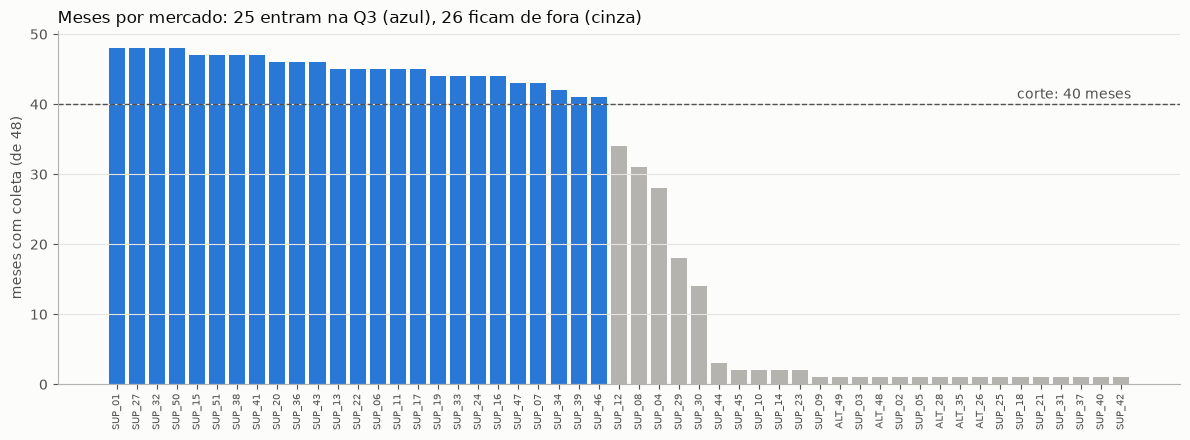

In [5]:
meses = aggregation.meses_por_mercado(base)
corte = config.MIN_MESES_MERCADO
selecionado = meses >= corte

fig, eixo = plt.subplots(figsize=(12, 4.5))
eixo.bar(range(len(meses)), meses.values, color=np.where(selecionado, AZUL, CINZA), width=0.8)
eixo.axhline(corte, color=TEXTO_2, linewidth=1, linestyle="--")
eixo.text(len(meses) - 0.5, corte + 0.8, f"corte: {corte} meses", ha="right", color=TEXTO_2)
eixo.set_xticks(range(len(meses)), meses.index, rotation=90, fontsize=7)
eixo.set_ylabel("meses com coleta (de 48)")
eixo.set_title(f"Meses por mercado: {selecionado.sum()} entram na Q3 (azul), {(~selecionado).sum()} ficam de fora (cinza)", loc="left")
eixo.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "02_meses_por_mercado.png", dpi=150)
plt.show()

In [6]:
# Quantos mercados sobram para cada corte possível
cortes = pd.DataFrame({"corte_meses": [30, 34, 35, 38, 40, 41, 42, 44, 46, 48]})
cortes["mercados"] = cortes["corte_meses"].map(lambda k: int((meses >= k).sum()))
cortes.to_csv(config.DIR_TABELAS / "02_mercados_por_corte.csv", index=False)
cortes

,corte_meses,mercados
0,30,27
1,34,26
2,35,25
3,38,25
4,40,25
5,41,25
6,42,23
7,44,20
8,46,11
9,48,4


**Leitura:** há um **vão natural** entre 34 e 41 meses: nenhum mercado tem de 35 a 40 meses. Os 25 mercados acima do vão têm de 41 a 48 meses (quase completos); abaixo dele, o próximo tem 34, e depois a contagem despenca (31, 28, 18, 14...). Os 16 estabelecimentos com 1 mês (inclusive os 5 `ALT_`) entraram e saíram da pesquisa.

Por isso **qualquer corte entre 35 e 41 seleciona exatamente os mesmos 25 mercados**, e o valor 40 de `config.MIN_MESES_MERCADO` (decisão 4) se mantém: o resultado não depende de escolher 38, 40 ou 41. Um corte mais alto (44 ou 46) jogaria fora mercados com 1 a 4 meses faltando, sem ganho real.

### Presença de cada mercado ao longo do tempo

Cada linha é um mercado e cada coluna um mês; azul = coletado. Mostra **quando** faltam os meses: se os mercados da Q3 têm buracos espalhados ou um período inteiro sem dados.

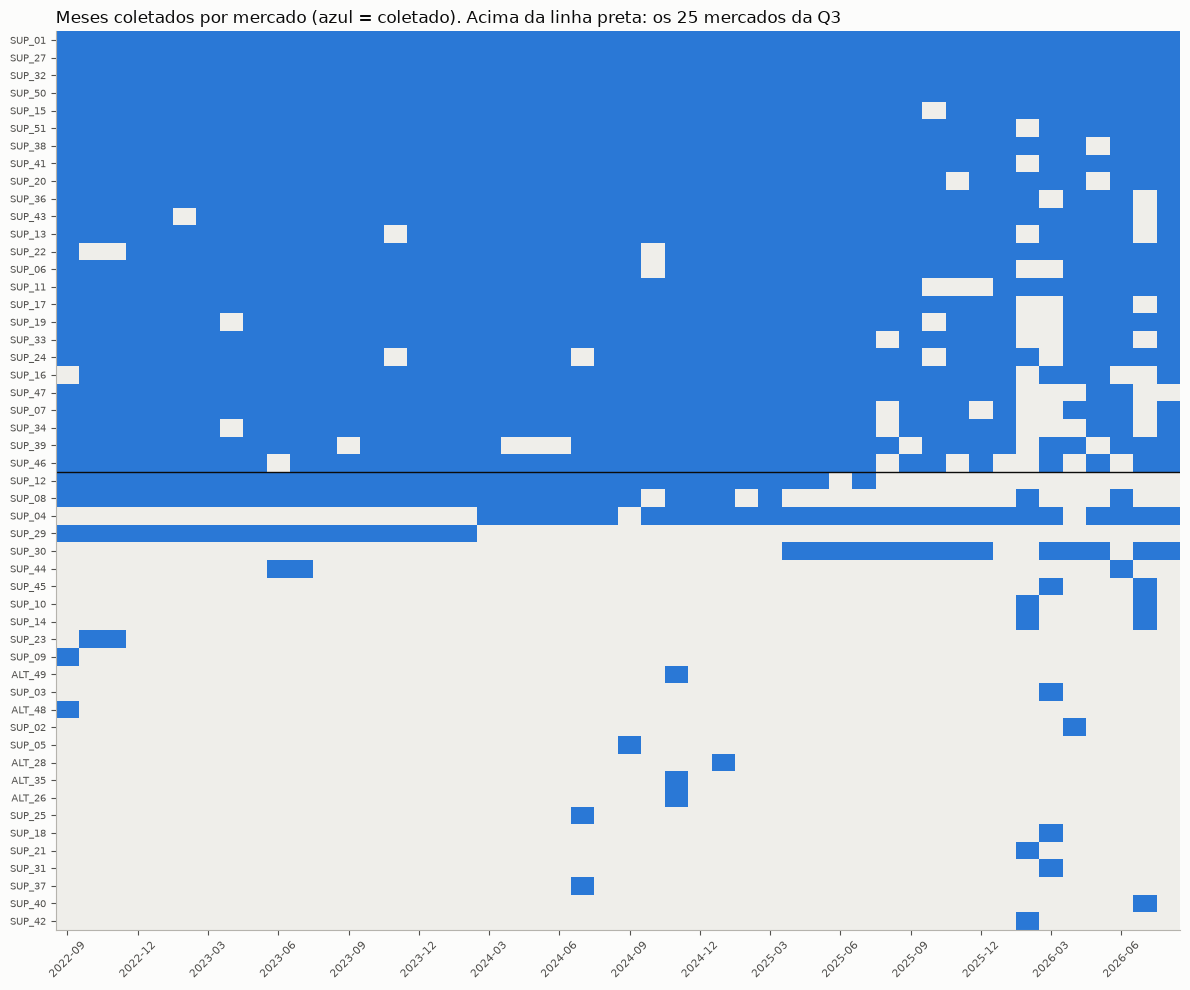

In [7]:
presenca = (base.assign(mes=base[config.COL_MES].dt.to_period("M"))
            .groupby([config.COL_MERCADO, "mes"]).size().unstack(fill_value=0).gt(0)
            .reindex(meses.index))

fig, eixo = plt.subplots(figsize=(12, 10))
eixo.imshow(presenca.values.astype(int), aspect="auto", cmap=ListedColormap(["#efeeea", AZUL]), interpolation="none")
eixo.set_yticks(range(len(presenca)), presenca.index, fontsize=7)
rotulos = [str(m) for m in presenca.columns]
eixo.set_xticks(range(0, len(rotulos), 3), rotulos[::3], rotation=45, fontsize=8)
eixo.axhline(selecionado.sum() - 0.5, color=TEXTO, linewidth=1)
eixo.grid(False)
eixo.set_title(f"Meses coletados por mercado (azul = coletado). Acima da linha preta: os {selecionado.sum()} mercados da Q3", loc="left")
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "02_presenca_mercados.png", dpi=150)
plt.show()

In [8]:
# Quantos dos mercados da Q3 faltam em cada mês (só meses com falta)
faltas_q3 = (~presenca[selecionado]).sum()
faltas_q3[faltas_q3 > 0]

mes
2022-09     1
2022-10     1
2022-11     1
2023-02     1
2023-04     2
2023-06     1
2023-09     1
2023-11     2
2024-04     1
2024-05     1
2024-06     1
2024-07     1
2024-10     2
2025-08     4
2025-09     1
2025-10     4
2025-11     3
2025-12     2
2026-01     1
2026-02    13
2026-03     9
2026-04     3
2026-05     3
2026-06     2
2026-07     9
2026-08     1
Freq: M, dtype: int64

**Leitura:** até jul/2025 os mercados da Q3 quase não têm falhas (no máximo 2 dos 25 ausentes por mês). Os buracos se concentram **a partir de ago/2025**, e os piores meses são **fev/2026** (13 dos 25 ausentes), **mar/2026** e **jul/2026** (9 cada). Fev/2026 é também o mês com menos mercados coletados na base toda (seção 2). Para a Q1 isso não é problema (a mediana de fev/2026 ainda reúne vários mercados), mas a **parte D** deve levar em conta ao medir a estabilidade dos grupos no tempo: o último período tem menos dados por mercado.

## 4. Quanto os preços variam de um mês para o outro

Contexto para a Q1: se o preço quase não muda de um mês para o outro, o baseline ingênuo ("o mês que vem custa o mesmo que este") já erra pouco e é difícil de bater.

- `variacao_total_%`: do primeiro ao último mês;
- `variacao_mensal_media_abs_%`: tamanho típico da mudança de um mês para o seguinte (é o erro relativo que o baseline comete);
- `meses_em_alta_%`: em quantos meses o preço subiu em relação ao anterior (é a proporção da classe "sobe" na avaliação de direção).

In [9]:
def resumo_variacao(serie: pd.DataFrame) -> pd.Series:
    preco = serie.sort_values("mes")["preco"].reset_index(drop=True)
    variacao = preco.pct_change().dropna()
    return pd.Series({
        "preco_inicial": preco.iloc[0],
        "preco_final": preco.iloc[-1],
        "variacao_total_%": 100 * (preco.iloc[-1] / preco.iloc[0] - 1),
        "variacao_mensal_media_abs_%": 100 * variacao.abs().mean(),
        "maior_alta_mensal_%": 100 * variacao.max(),
        "maior_queda_mensal_%": 100 * variacao.min(),
        "meses_em_alta_%": 100 * (variacao > 0).mean(),
    })

variacao = (geral.groupby("produto")[["mes", "preco"]].apply(resumo_variacao)
            .round(2).sort_values("variacao_mensal_media_abs_%", ascending=False))
variacao.to_csv(config.DIR_TABELAS / "02_variacao_mensal.csv")
variacao

,preco_inicial,preco_final,variacao_total_%,variacao_mensal_media_abs_%,maior_alta_mensal_%,maior_queda_mensal_%,meses_em_alta_%
produto,,,,,,,
Batata,5.08,5.99,18.03,19.88,117.39,-39.49,48.94
Tomate,4.99,7.79,56.11,14.24,46.73,-47.82,46.81
Banana Nanica,5.99,6.99,16.69,7.83,29.41,-22.03,48.94
Banana Prata,8.99,11.94,32.87,6.18,20.11,-16.68,42.55
Leite,5.74,5.99,4.36,4.12,19.23,-9.56,42.55
Feijão,9.25,10.19,10.22,4.02,13.96,-9.62,44.68
Arroz,4.95,5.07,2.53,3.40,13.41,-13.06,55.32
Óleo,9.66,8.65,-10.39,3.29,13.59,-8.68,46.81
Farinha de Trigo,6.37,5.49,-13.81,3.25,9.31,-10.18,46.81


**Leitura:** os produtos se dividem em dois grupos.

- **Hortifrúti varia muito:** batata muda em média **19,9%** de um mês para o outro e tomate **14,2%** (safra e clima); as bananas, 6–8%. Aqui o baseline ingênuo erra bastante, então é onde um modelo tem mais espaço para ganhar (e também mais chance de errar).
- **Grãos e industrializados variam pouco:** de **1,9%** (pão francês) a **4,1%** (leite) por mês. Para eles, o baseline ingênuo já erra pouco e deve ser difícil de bater.
- **Variação pequena por mês não quer dizer preço parado:** o café subiu **58%** em 4 anos, mas só ~3% por mês em média. Tendência lenta é algo que um modelo com lags pode captar e o baseline não.
- **Direção equilibrada:** a proporção de meses em alta fica entre **43% e 55%** em todos os produtos, então as classes "sobe" e "não sobe" da avaliação de direção (decisão 7) são razoavelmente balanceadas e a acurácia não fica inflada por uma classe dominante.

## Resumo para as outras partes

- **Parte C (Q1):** a série geral está completa (14 produtos × 48 meses, sem mês vazio) e cada mediana reúne em média ~27 mercados. Use `aggregation.serie_geral(data_loading.carregar_base_limpa())`. A tabela `02_variacao_mensal.csv` dá o tamanho típico do erro do baseline por produto.
- **Parte D (Q3):** `config.MIN_MESES_MERCADO = 40` seleciona 25 mercados; qualquer corte entre 35 e 41 dá os mesmos 25. Use `aggregation.selecionar_mercados(base)` e `aggregation.series_por_mercado(base, mercados)`.